<a href="https://colab.research.google.com/github/prattayabsmrstu/GioAI_Gopalganj/blob/Python-Scripts/Turbidity_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import json
import os

FNAME = 'Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv'

if not os.path.exists(FNAME):
    from google.colab import files
    print('আপলোড ডায়ালগে D:\\Advance Wetland Monitoring\\Gopalganj_Turbidity_Data\\ থেকে ফাইলটি বেছে নিন')
    files.upload()

if not os.path.exists(FNAME):
    print('আপলোড হয়নি। বর্তমান ফোল্ডারে আছে:', os.listdir('.'))
else:
    df = pd.read_csv(FNAME)
    print('Shape:', df.shape)
    print('\nMissing values:\n', df.isnull().sum())
    print('\nNDTI describe:\n', df['NDTI'].describe())
    print('\nSeason counts:\n', df['Season'].value_counts())
    print('\nYear counts:\n', df['Year'].value_counts().sort_index())
    print('\nDriver describe:\n',
          df[['Rainfall','Rain_30d','Rain_7d','LST','Elevation','DistToWater']].describe())

    coords = df['.geo'].apply(lambda s: json.loads(s)['coordinates'])
    df['lon'] = coords.apply(lambda c: c[0])
    df['lat'] = coords.apply(lambda c: c[1])
    print('\nlon range:', df['lon'].min(), df['lon'].max())
    print('lat range:', df['lat'].min(), df['lat'].max())
    print('\nপ্রস্তুত। সারি:', len(df))

আপলোড ডায়ালগে D:\Advance Wetland Monitoring\Gopalganj_Turbidity_Data\ থেকে ফাইলটি বেছে নিন


Saving Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv to Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv
Shape: (12106, 18)

Missing values:
 system:index    0
B11             0
B2              0
B3              0
B4              0
B8              0
DistToWater     0
Elevation       0
LST             0
MNDWI           0
NDTI            0
NDWI            0
Rain_30d        0
Rain_7d         0
Rainfall        0
Season          0
Year            0
.geo            0
dtype: int64

NDTI describe:
 count    12106.000000
mean        -0.108677
std          0.064725
min         -0.900000
25%         -0.146678
50%         -0.105396
75%         -0.067569
max          0.251701
Name: NDTI, dtype: float64

Season counts:
 Season
DryWinter      4259
PostMonsoon    4064
Monsoon        3201
PreMonsoon      582
Name: count, dtype: int64

Year counts:
 Year
2019    1237
2020    1540
2021    1937
2022    2258
2023    1115
2024    1823
2025    2196
Name: count, dtype: int64

Driver describe:
           

In [6]:
!pip install -q shap

=== Random Forest Performance ===
R2  : 0.4155
RMSE: 0.0484
MAE : 0.0359

=== Gini Importance ===
    feature  importance
DistToWater    0.231282
        LST    0.188123
   Rainfall    0.186713
    Rain_7d    0.151132
   Rain_30d    0.150556
  Elevation    0.062223
       Year    0.029972


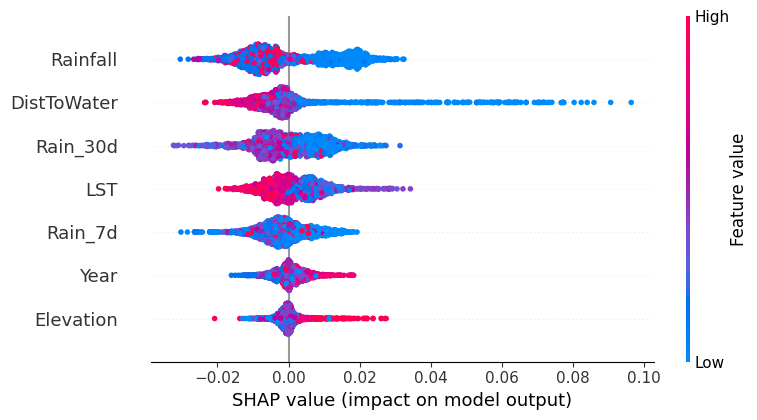

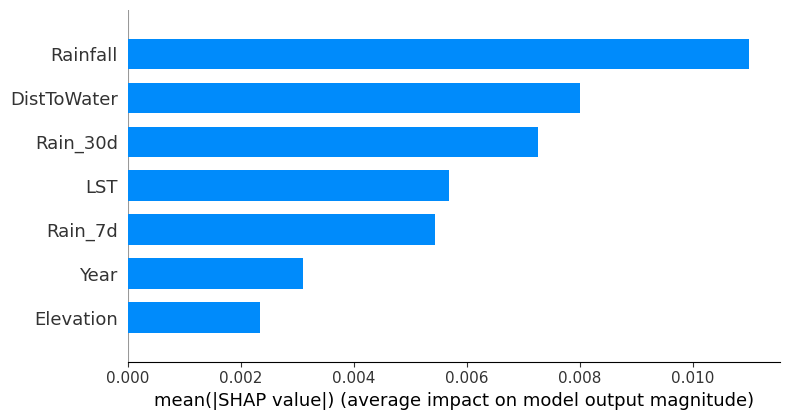

<Figure size 640x480 with 0 Axes>

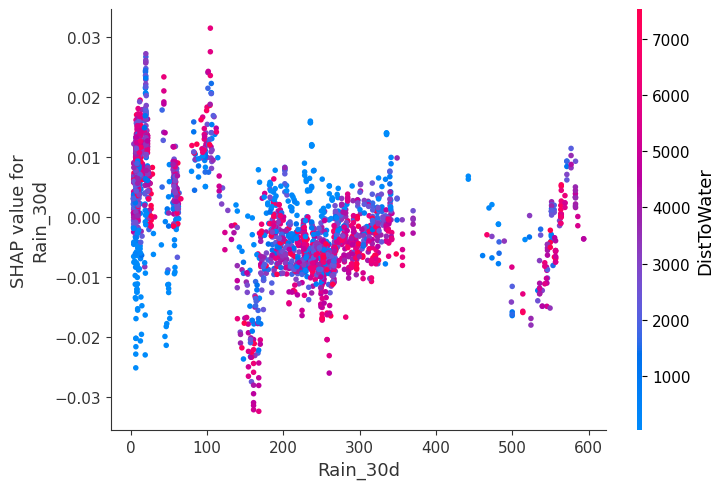

In [7]:
import pandas as pd, numpy as np, json
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import shap
import matplotlib.pyplot as plt

df = pd.read_csv('Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv')

features = ['Rainfall','Rain_30d','Rain_7d','LST','Elevation','DistToWater','Year']
target = 'NDTI'

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(
    n_estimators=500, min_samples_leaf=3, max_features='sqrt',
    random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

pred = rf.predict(X_test)
print('=== Random Forest Performance ===')
print('R2  :', round(r2_score(y_test, pred), 4))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test, pred)), 4))
print('MAE :', round(mean_absolute_error(y_test, pred), 4))

# Gini importance
imp = pd.DataFrame({'feature': features,
                    'importance': rf.feature_importances_}
                  ).sort_values('importance', ascending=False)
print('\n=== Gini Importance ===')
print(imp.to_string(index=False))

# SHAP
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

plt.figure()
shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.savefig('SHAP_summary.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure()
shap.summary_plot(shap_values, X_test, plot_type='bar', show=False)
plt.tight_layout()
plt.savefig('SHAP_bar.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure()
shap.dependence_plot('Rain_30d', shap_values, X_test, show=False)
plt.tight_layout()
plt.savefig('SHAP_dependence_Rain30.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
import pandas as pd, numpy as np, json
from sklearn.model_selection import GroupKFold, cross_val_score, train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.inspection import permutation_importance
import shap, matplotlib.pyplot as plt

df = pd.read_csv('Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv')

coords = df['.geo'].apply(lambda s: json.loads(s)['coordinates'])
df['lon'] = coords.apply(lambda c: c[0])
df['lat'] = coords.apply(lambda c: c[1])

# প্রতিটি সিজনাল কম্পোজিট = একটি গ্রুপ
df['group'] = df['Year'].astype(str) + '_' + df['Season']
print('গ্রুপ সংখ্যা:', df['group'].nunique())

features = ['Rainfall','Rain_30d','Rain_7d','LST','Elevation','DistToWater','Year']
target = 'NDTI'

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                            max_features='sqrt', random_state=42, n_jobs=-1)

# ---- টেস্ট ১: র‍্যান্ডম স্প্লিট (মূল ফলাফল, interpolation scenario) ----
X_tr, X_te, y_tr, y_te = train_test_split(df[features], df[target],
                                            test_size=0.2, random_state=42)
rf.fit(X_tr, y_tr)
p = rf.predict(X_te)
print('\n=== RANDOM SPLIT ===')
print('R2  :', round(r2_score(y_te, p), 4))
print('RMSE:', round(np.sqrt(mean_squared_error(y_te, p)), 4))

# ---- টেস্ট ২: Grouped CV, একটি কম্পোজিট সরিয়ে (generalization) ----
gkf = GroupKFold(n_splits=7)
scores = cross_val_score(rf, df[features], df[target],
                         groups=df['group'], cv=gkf,
                         scoring='r2', n_jobs=-1)
print('\n=== GROUPED CV (leave one composite out) ===')
print('R2 per fold:', np.round(scores, 4))
print('Mean R2     :', round(scores.mean(), 4))
print('Std  R2     :', round(scores.std(), 4))
print('Range       :', round(scores.min(), 4), 'to', round(scores.max(), 4))

# ---- টেস্ট ৩: Permutation importance (কলনারিতা-সহনশীল) ----
perm = permutation_importance(rf, X_te, y_te, n_repeats=10,
                               random_state=42, n_jobs=-1)
pimp = pd.DataFrame({'feature': features,
                     'perm_importance': perm.importances_mean,
                     'std': perm.importances_std}
                    ).sort_values('perm_importance', ascending=False)
print('\n=== PERMUTATION IMPORTANCE ===')
print(pimp.to_string(index=False))

গ্রুপ সংখ্যা: 28

=== RANDOM SPLIT ===
R2  : 0.4139
RMSE: 0.0485

=== GROUPED CV (leave one composite out) ===
R2 per fold: [0.0054 0.1584 0.1268 0.3132 0.1145 0.2163 0.2404]
Mean R2     : 0.1679
Std  R2     : 0.0924
Range       : 0.0054 to 0.3132

=== PERMUTATION IMPORTANCE ===
    feature  perm_importance      std
DistToWater         0.254485 0.019630
   Rainfall         0.138613 0.008476
   Rain_30d         0.124989 0.010548
    Rain_7d         0.072863 0.003833
        LST         0.059443 0.006350
  Elevation         0.032055 0.004297
       Year         0.023667 0.002906


In [9]:
import pandas as pd, numpy as np, json
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

df = pd.read_csv('Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv')
coords = df['.geo'].apply(lambda s: json.loads(s)['coordinates'])
df['lon'] = coords.apply(lambda c: c[0])
df['lat'] = coords.apply(lambda c: c[1])
df['group'] = df['Year'].astype(str) + '_' + df['Season']

features = ['Rainfall','Rain_30d','Rain_7d','LST','Elevation','DistToWater','Year']
target = 'NDTI'
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                            max_features='sqrt', random_state=42, n_jobs=-1)

# ---- A. Spatial block CV: অচেনা স্থানে ম্যাপিং ----
df['block'] = (np.floor(df['lon']/0.05).astype(str) + '_' +
               np.floor(df['lat']/0.05).astype(str))
print('spatial blocks:', df['block'].nunique())

sc = cross_val_score(rf, df[features], df[target], groups=df['block'],
                     cv=GroupKFold(n_splits=10), scoring='r2', n_jobs=-1)
print('\n=== SPATIAL BLOCK CV ===')
print('R2 per fold:', np.round(sc, 4))
print('Mean R2     :', round(sc.mean(), 4))
print('Std  R2     :', round(sc.std(), 4))

# ---- B. কোন কম্পোজিটে মডেল ভেঙে, এবং কেন ----
rows = []
gkf = GroupKFold(n_splits=7)
for i, (tr, te) in enumerate(gkf.split(df[features], df[target], df['group'])):
    m = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                              max_features='sqrt', random_state=42,
                              n_jobs=-1).fit(df[features].iloc[tr], df[target].iloc[tr])
    r = r2_score(df[target].iloc[te], m.predict(df[features].iloc[te]))
    trn_min = df['Rainfall'].iloc[tr].min()
    trn_max = df['Rainfall'].iloc[tr].max()
    for g in df['group'].iloc[te].unique():
        rv = df.loc[df['group'] == g, 'Rainfall'].iloc[0]
        rows.append({'fold': i, 'composite': g, 'R2': round(r, 4),
                     'rain': round(rv, 1),
                     'outside_train_range': bool(rv < trn_min or rv > trn_max)})

d = pd.DataFrame(rows).sort_values('R2')
print('\n=== FOLD DIAGNOSTIC ===')
print(d.to_string(index=False))
print('\noutside range মানে:', d['outside_train_range'].sum(), '/', len(d))

spatial blocks: 73


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



=== SPATIAL BLOCK CV ===
R2 per fold: [0.3553 0.3569 0.3662 0.2662 0.1661 0.2837 0.1977 0.3214 0.2826 0.296 ]
Mean R2     : 0.2892
Std  R2     : 0.0633

=== FOLD DIAGNOSTIC ===
 fold        composite     R2   rain  outside_train_range
    0   2022_DryWinter 0.0054   90.9                False
    0  2023_PreMonsoon 0.0054  255.1                False
    0     2024_Monsoon 0.0054 1397.2                False
    4     2019_Monsoon 0.1145 1309.6                False
    4     2025_Monsoon 0.1145 1484.8                False
    4     2023_Monsoon 0.1145 1075.9                False
    4   2020_DryWinter 0.1145   48.4                False
    2  2019_PreMonsoon 0.1268  424.8                False
    2     2021_Monsoon 0.1268 1501.7                False
    2 2023_PostMonsoon 0.1268  235.5                False
    2 2019_PostMonsoon 0.1268  210.3                False
    1  2020_PreMonsoon 0.1584  407.8                False
    1 2024_PostMonsoon 0.1584  265.7                False
    1 2020

In [10]:
df = pd.read_csv('Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv')
coords = df['.geo'].apply(lambda s: json.loads(s)['coordinates'])
df['lon'] = coords.apply(lambda c: c[0])
df['lat'] = coords.apply(lambda c: c[1])

# বাকি দুটি ইনডেক্স CSV-তে নেই, B3 ও B4 থেকে হিসাব করে নেওয়া হচ্ছে
df['GR_Ratio'] = df['B3'] / df['B4']
df['RedRefl'] = df['B4']

plt.rcParams.update({'font.size': 11, 'figure.dpi': 150})

=== Spearman correlation matrix ===
           NDTI  MNDWI   NDWI  GR_Ratio  RedRefl     B3     B2     B8
NDTI      1.000  0.113  0.143    -1.000    0.425  0.160  0.200 -0.022
MNDWI     0.113  1.000  0.733    -0.113   -0.020 -0.046 -0.029 -0.647
NDWI      0.143  0.733  1.000    -0.143    0.116  0.095  0.112 -0.723
GR_Ratio -1.000 -0.113 -0.143     1.000   -0.425 -0.160 -0.200  0.022
RedRefl   0.425 -0.020  0.116    -0.425    1.000  0.950  0.926  0.492
B3        0.160 -0.046  0.095    -0.160    0.950  1.000  0.949  0.542
B2        0.200 -0.029  0.112    -0.200    0.926  0.949  1.000  0.505
B8       -0.022 -0.647 -0.723     0.022    0.492  0.542  0.505  1.000


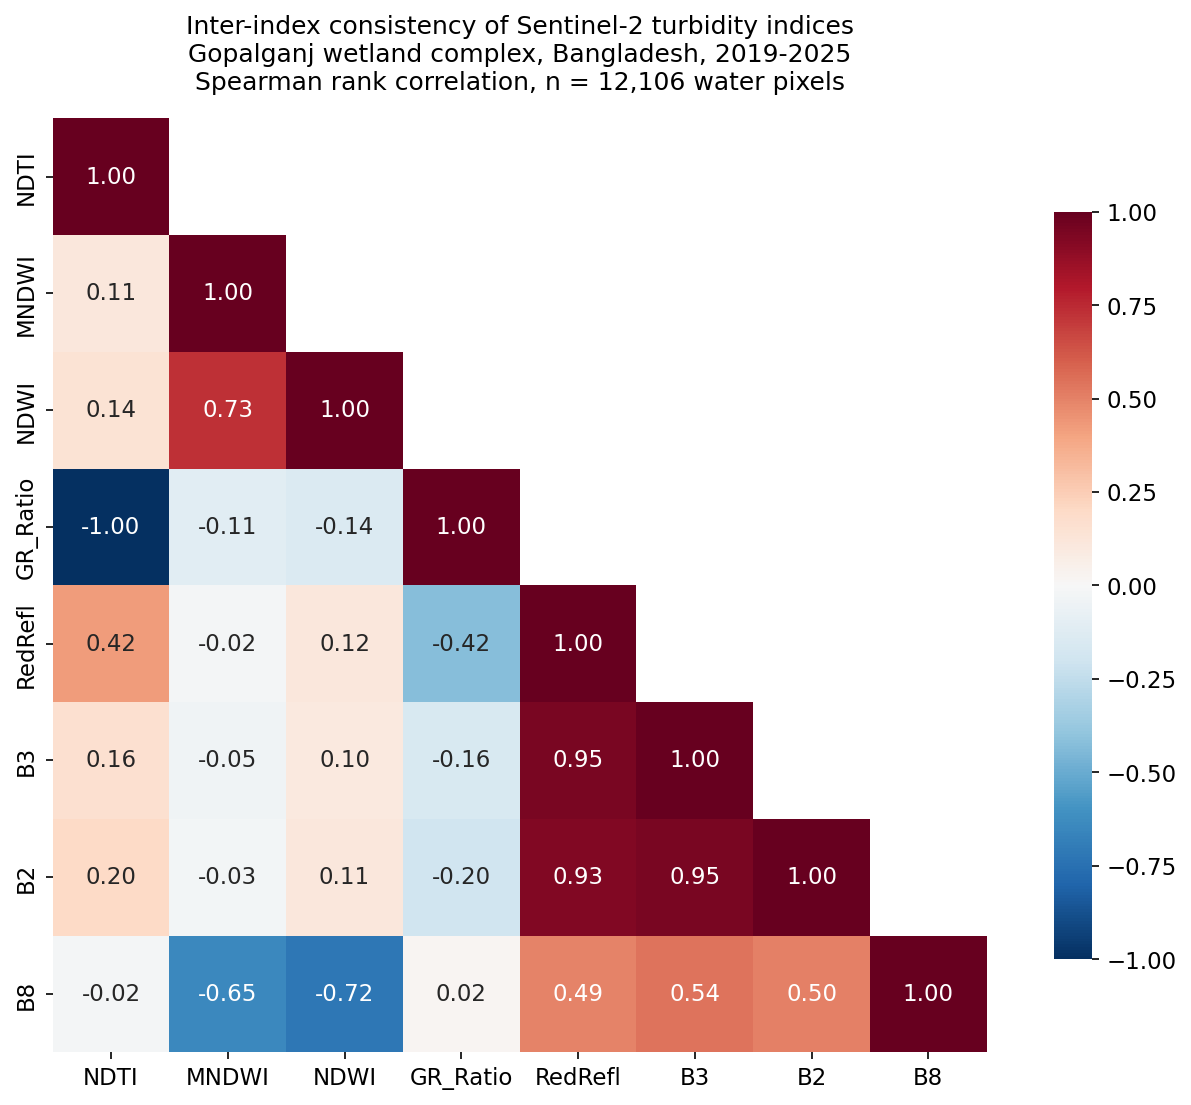


=== NDTI against each alternative formulation ===
NDTI vs MNDWI     : rho = +0.1125, p = 2.121e-35
NDTI vs NDWI      : rho = +0.1430, p = 2.339e-56
NDTI vs GR_Ratio  : rho = -1.0000, p = 0.000e+00
NDTI vs RedRefl   : rho = +0.4249, p = 0.000e+00
NDTI vs B3        : rho = +0.1595, p = 7.851e-70
NDTI vs B2        : rho = +0.2005, p = 5.655e-110
NDTI vs B8        : rho = -0.0222, p = 1.470e-02

=== Composite level table (28 composites) ===
 Year      Season   ndti  rainfall  rain30   rain7    lst  rain_cum    n
 2019   DryWinter -0.060    57.975   9.227   0.936 24.106    57.975  375
 2019  PreMonsoon -0.113   424.830  39.652   3.283 29.365   482.805   61
 2019     Monsoon -0.114  1309.600  92.540  11.708 29.533  1792.405  296
 2019 PostMonsoon -0.130   210.336 236.470  20.745 28.404  2002.742  505
 2020   DryWinter -0.075    48.408  61.188   0.764 23.962    48.408  560
 2020  PreMonsoon -0.136   407.758  12.390   1.392 30.411   456.167   75
 2020     Monsoon -0.132  1258.243 262.881  88.

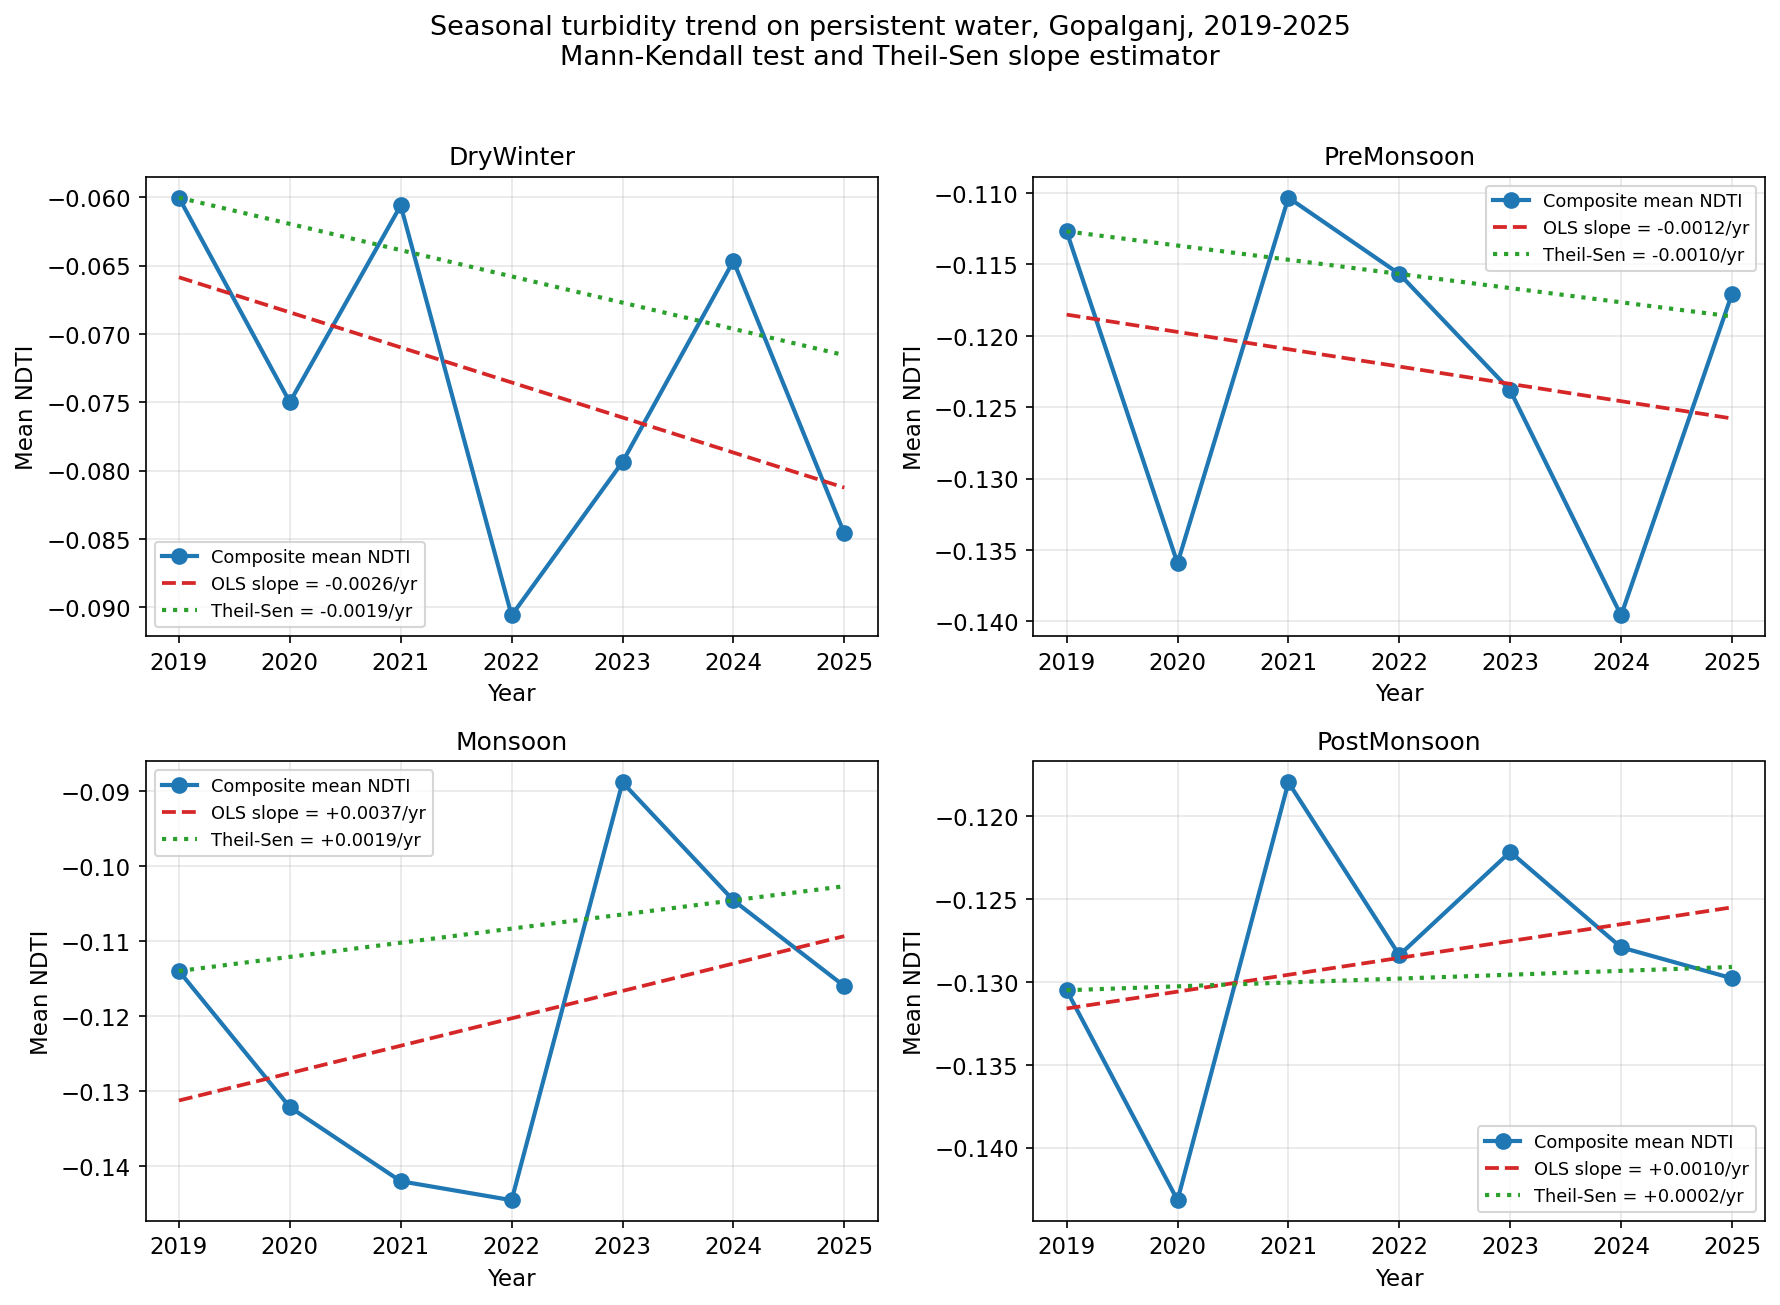


=== Partial dependence (manual computation) ===


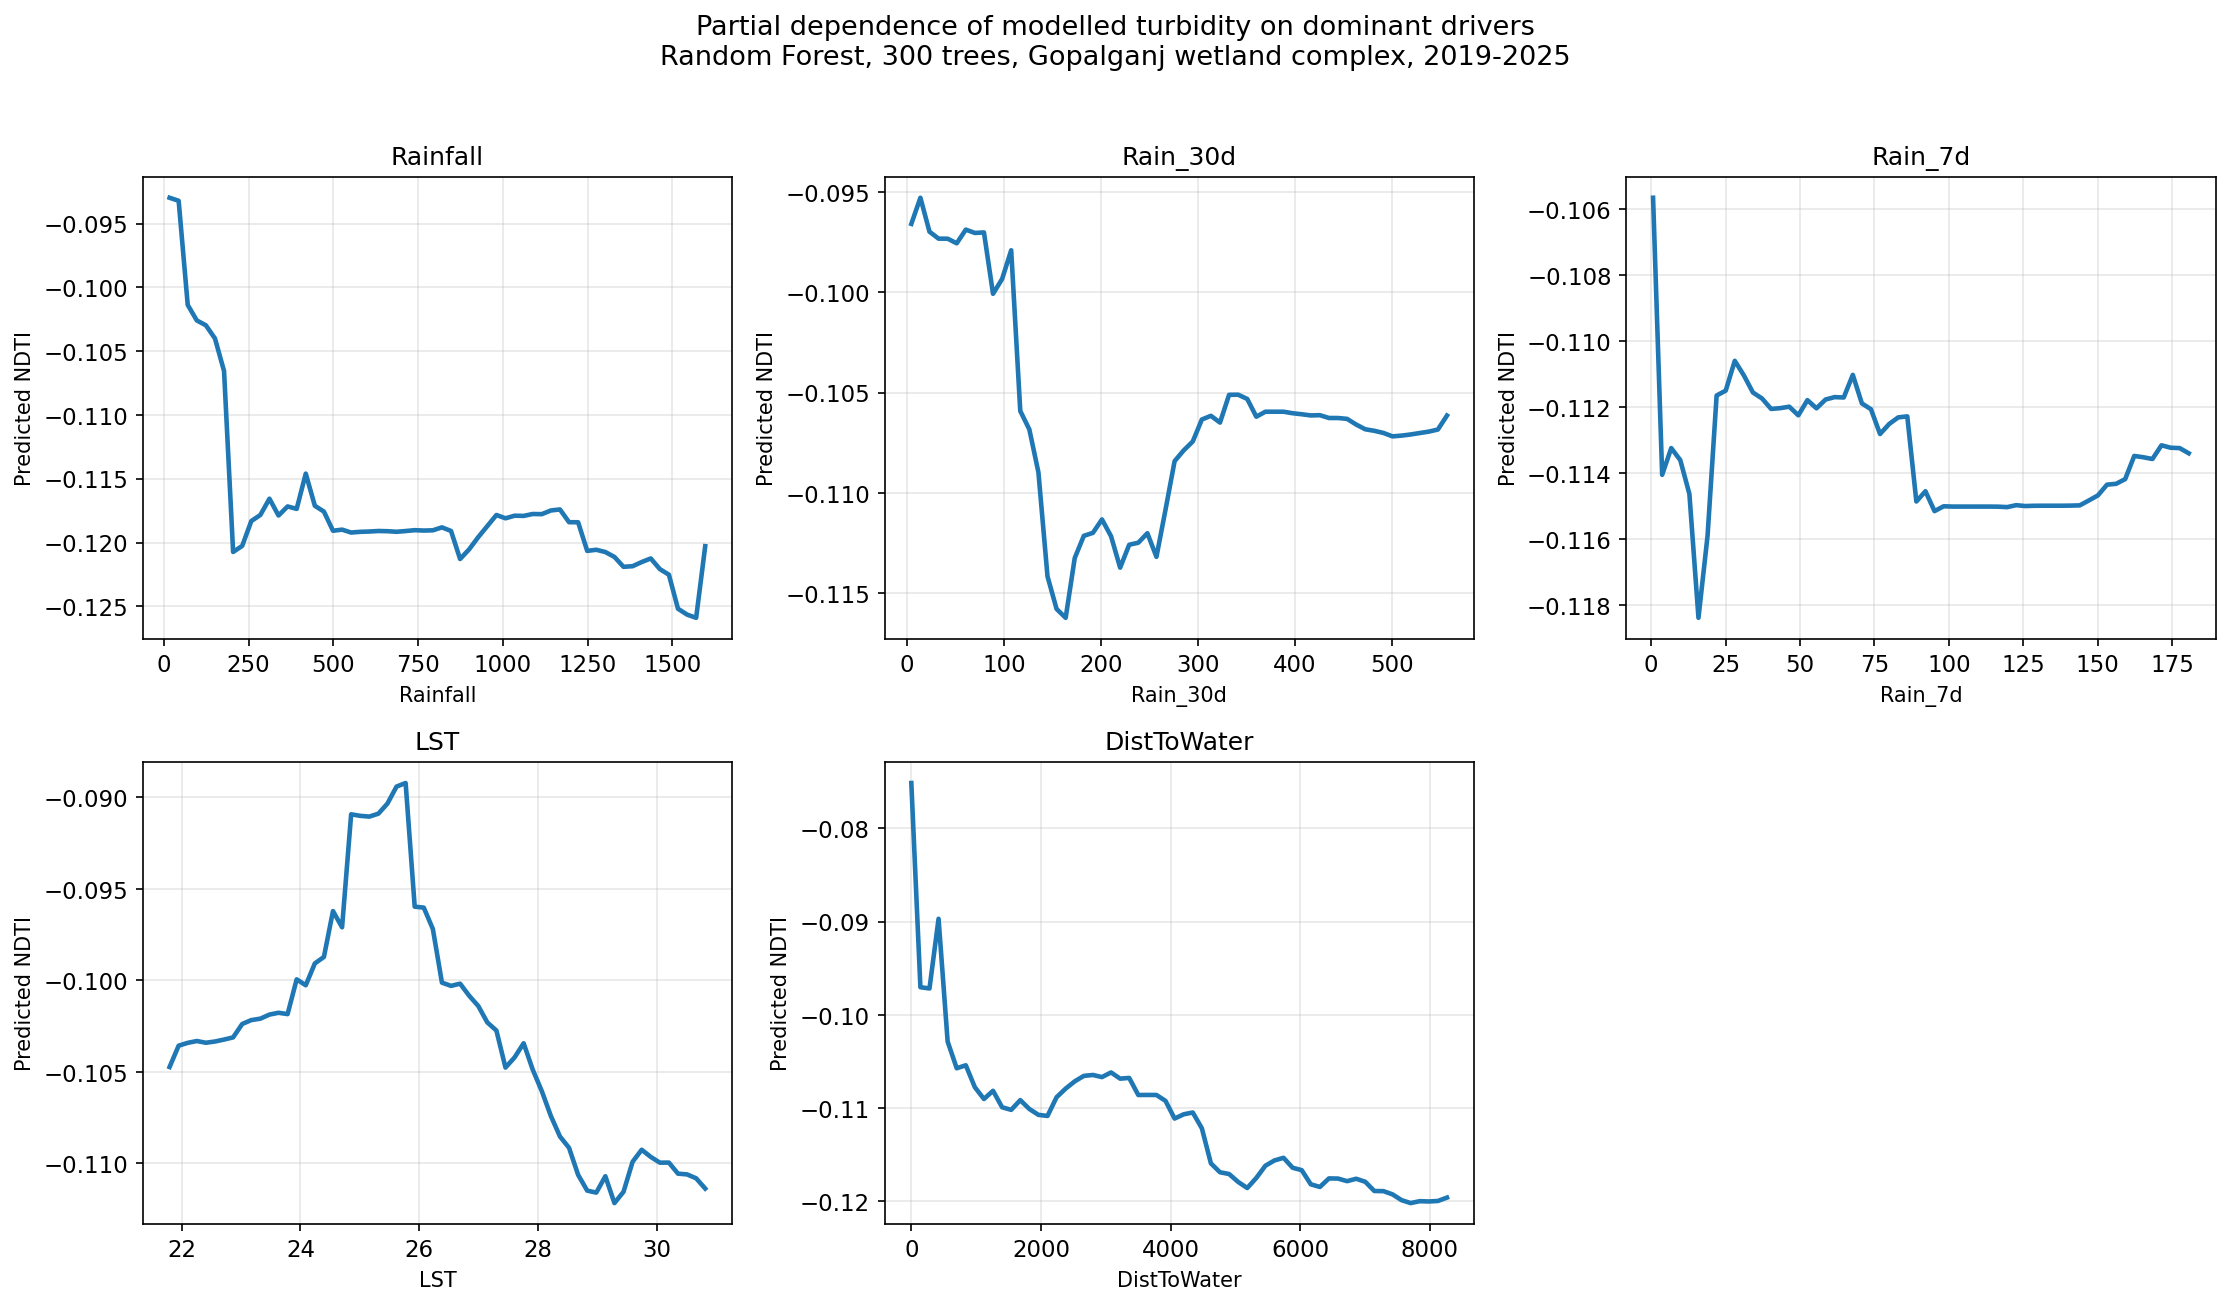


DONE. Three figures saved:
  Fig_InterIndex_Correlation.png
  Fig_Seasonal_Trend.png
  Fig_PartialDependence.png


In [11]:
import pandas as pd, numpy as np, json
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# ================= লোড =================
df = pd.read_csv('Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv')
coords = df['.geo'].apply(lambda s: json.loads(s)['coordinates'])
df['lon'] = coords.apply(lambda c: c[0])
df['lat'] = coords.apply(lambda c: c[1])

# CSV-তে নেই এমন দুটি ইনডেক্স, ব্যান্ড থেকে হিসাব করে নেওয়া হলো
df['GR_Ratio'] = df['B3'] / df['B4']
df['RedRefl'] = df['B4']

plt.rcParams.update({'font.size': 11, 'figure.dpi': 150})

# ================= ১. ইন্টার-ইনডেক্স করেলেশন =================
idx_cols = ['NDTI', 'MNDWI', 'NDWI', 'GR_Ratio', 'RedRefl', 'B3', 'B2', 'B8']
corr = df[idx_cols].corr(method='spearman')

print('=== Spearman correlation matrix ===')
print(corr.round(3).to_string())

fig, ax = plt.subplots(figsize=(9.5, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, vmin=-1, vmax=1, cmap='RdBu_r',
            annot=True, fmt='.2f', square=True, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Inter-index consistency of Sentinel-2 turbidity indices\n'
             'Gopalganj wetland complex, Bangladesh, 2019-2025\n'
             'Spearman rank correlation, n = 12,106 water pixels',
             fontsize=12, pad=14)
plt.tight_layout()
plt.savefig('Fig_InterIndex_Correlation.png', dpi=300, bbox_inches='tight')
plt.show()

print('\n=== NDTI against each alternative formulation ===')
for c in ['MNDWI', 'NDWI', 'GR_Ratio', 'RedRefl', 'B3', 'B2', 'B8']:
    r, p = stats.spearmanr(df['NDTI'], df[c])
    print(f'NDTI vs {c:9s} : rho = {r:+.4f}, p = {p:.3e}')

# ================= ২. কম্পোজিট-স্তরের টেবিল =================
order = {'DryWinter': 0, 'PreMonsoon': 1, 'Monsoon': 2, 'PostMonsoon': 3}
SEASONS = ['DryWinter', 'PreMonsoon', 'Monsoon', 'PostMonsoon']

comp = (df.groupby(['Year', 'Season'])
          .agg(ndti=('NDTI', 'mean'),
               rainfall=('Rainfall', 'first'),
               rain30=('Rain_30d', 'first'),
               rain7=('Rain_7d', 'first'),
               lst=('LST', 'mean'),
               n=('NDTI', 'size'))
          .reset_index())

comp['sorder'] = comp['Season'].map(order)
comp = comp.sort_values(['Year', 'sorder']).reset_index(drop=True)
comp['rain_cum'] = comp.groupby('Year')['rainfall'].cumsum()

print('\n=== Composite level table (28 composites) ===')
print(comp[['Year', 'Season', 'ndti', 'rainfall', 'rain30', 'rain7',
             'lst', 'rain_cum', 'n']].round(3).to_string(index=False))

# ================= ৩. ল্যাগড বৃষ্টিপাত রেসপন্স =================
piv_rain = comp.pivot(index='Year', columns='Season', values='rain_cum')
piv_ndti = comp.pivot(index='Year', columns='Season', values='ndti')
years = sorted(comp['Year'].unique())

def safe_pearson(x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    m = ~(np.isnan(x) | np.isnan(y))
    x, y = x[m], y[m]
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan, np.nan, len(x)
    r, p = stats.pearsonr(x, y)
    return r, p, len(x)

print('\n=== Same-year: NDTI vs cumulative rainfall ===')
for s in SEASONS:
    r, p, n = safe_pearson(piv_rain[s].loc[years], piv_ndti[s].loc[years])
    print(f'{s:12s}: r = {r:+.4f}, p = {p:.4f}  (n={n})')

print('\n=== One-year lag: NDTI in year t vs cumulative rainfall in year t-1 ===')
for s in SEASONS:
    r, p, n = safe_pearson(piv_rain[s].loc[years[:-1]],
                            piv_ndti[s].loc[years[1:]])
    print(f'{s:12s}: r = {r:+.4f}, p = {p:.4f}  (n={n})')

print('\n=== Two-year lag ===')
for s in SEASONS:
    r, p, n = safe_pearson(piv_rain[s].loc[years[:-2]],
                            piv_ndti[s].loc[years[2:]])
    print(f'{s:12s}: r = {r:+.4f}, p = {p:.4f}  (n={n})')

# ================= ৪. ম্যান-কেন্ডাল ও থিল-সেন =================
def mann_kendall(y):
    y = np.asarray(y, dtype=float)
    n = len(y)
    s = sum(np.sign(y[j] - y[i]) for i in range(n - 1) for j in range(i + 1, n))
    var_s = n * (n - 1) * (2 * n + 5) / 18
    z = (s - np.sign(s)) / np.sqrt(var_s)
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    slope = stats.linregress(np.arange(n), y)[0]
    return z, p, slope

def theil_sen(y):
    y = np.asarray(y, dtype=float)
    n = len(y)
    slopes = [(y[j] - y[i]) / (j - i)
              for i in range(n - 1) for j in range(i + 1, n)]
    return float(np.median(slopes))

print('\n=== Mann-Kendall trend per season, 2019-2025 ===')
for s in SEASONS:
    sub = comp[comp['Season'] == s].sort_values('Year')
    z, p, slope = mann_kendall(sub['ndti'].values)
    ts = theil_sen(sub['ndti'].values)
    sig = 'SIGNIFICANT' if p < 0.05 else 'not significant'
    print(f'{s:12s}: MK z = {z:+.3f}, p = {p:.4f} ({sig}) | '
          f'OLS = {slope:+.5f}/yr | Theil-Sen = {ts:+.5f}/yr')

ann = comp.groupby('Year')['ndti'].mean().loc[years]
z, p, slope = mann_kendall(ann.values)
print(f'\nAnnual mean : MK z = {z:+.3f}, p = {p:.4f} | '
      f'OLS = {slope:+.5f}/yr | Theil-Sen = {theil_sen(ann.values):+.5f}/yr')

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
for ax, s in zip(axes.ravel(), SEASONS):
    sub = comp[comp['Season'] == s].sort_values('Year')
    x = sub['Year'].values
    y = sub['ndti'].values
    ax.plot(x, y, 'o-', color='#1f77b4', lw=2, ms=7, label='Composite mean NDTI')
    m, b = np.polyfit(x, y, 1)
    ax.plot(x, m * x + b, '--', color='#d62728', lw=1.8,
            label=f'OLS slope = {m:+.4f}/yr')
    ts = theil_sen(y)
    ax.plot(x, y[0] + ts * (x - x[0]), ':', color='#2ca02c', lw=2,
            label=f'Theil-Sen = {ts:+.4f}/yr')
    ax.set_title(f'{s}', fontsize=12)
    ax.set_xlabel('Year'); ax.set_ylabel('Mean NDTI')
    ax.grid(alpha=0.3); ax.legend(fontsize=8.5)
fig.suptitle('Seasonal turbidity trend on persistent water, Gopalganj, 2019-2025\n'
             'Mann-Kendall test and Theil-Sen slope estimator',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('Fig_Seasonal_Trend.png', dpi=300, bbox_inches='tight')
plt.show()

# ================= ৫. পার্শিয়াল ডিপেনডেন্স =================
print('\n=== Partial dependence (manual computation) ===')
features = ['Rainfall', 'Rain_30d', 'Rain_7d', 'LST',
            'Elevation', 'DistToWater', 'Year']
X = df[features].copy()
y = df['NDTI'].copy()

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                            max_features='sqrt', random_state=42, n_jobs=-1)
rf.fit(X, y)

grid = {
    'Rainfall':    np.linspace(df['Rainfall'].quantile(.02), df['Rainfall'].quantile(.98), 60),
    'Rain_30d':    np.linspace(df['Rain_30d'].quantile(.02), df['Rain_30d'].quantile(.98), 60),
    'Rain_7d':     np.linspace(df['Rain_7d'].quantile(.02), df['Rain_7d'].quantile(.98), 60),
    'LST':         np.linspace(df['LST'].quantile(.02), df['LST'].quantile(.98), 60),
    'DistToWater': np.linspace(df['DistToWater'].quantile(.02), df['DistToWater'].quantile(.98), 60),
}
base = X.iloc[:3000].copy()

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (f, g) in zip(axes.ravel(), grid.items()):
    vals = []
    for v in g:
        t = base.copy()
        t[f] = v
        vals.append(rf.predict(t).mean())
    ax.plot(g, vals, '-', color='#1f77b4', lw=2.2)
    ax.set_xlabel(f, fontsize=10)
    ax.set_ylabel('Predicted NDTI', fontsize=10)
    ax.set_title(f, fontsize=12)
    ax.grid(alpha=0.3)
axes.ravel()[-1].axis('off')
fig.suptitle('Partial dependence of modelled turbidity on dominant drivers\n'
             'Random Forest, 300 trees, Gopalganj wetland complex, 2019-2025',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('Fig_PartialDependence.png', dpi=300, bbox_inches='tight')
plt.show()

print('\nDONE. Three figures saved:')
print('  Fig_InterIndex_Correlation.png')
print('  Fig_Seasonal_Trend.png')
print('  Fig_PartialDependence.png')

In [12]:
import pandas as pd, numpy as np, json
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import shap

df = pd.read_csv('Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv')

# ১. নাম সংশোধন ও ট্রাঙ্কেশন যাচাই
df = df.rename(columns={'DistToWater': 'DistToPermanentWater'})
d = df['DistToPermanentWater']
print('=== DistToPermanentWater diagnostics ===')
print(d.describe())
for lim in [7680, 8000, 9000]:
    print(f'  samples > {lim} m : {(d > lim).sum()}  ({100*(d > lim).mean():.2f}%)')

# ২. মডেল ও SHAP
features = ['Rainfall','Rain_30d','Rain_7d','LST','Elevation',
            'DistToPermanentWater','Year']
X = df[features].copy(); y = df['NDTI'].copy()

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                            max_features='sqrt', random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)

explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(X_te)

# ৩. প্রতিটি ড্রাইভারের জন্য কুইন্টাইল-ভিত্তিক SHAP দিক
print('\n=== Mean SHAP by feature quintile (direction of effect) ===')
rows = []
for i, f in enumerate(features):
    q = pd.qcut(X_te[f], 5, labels=False, duplicates='drop')
    if pd.isna(q).any():
        continue
    q = pd.Series(q, index=X_te.index)
    for k in sorted(q.unique()):
        m = q == k
        rows.append({'feature': f, 'quintile': int(k)+1,
                     'feature_value': float(X_te[f][m].mean()),
                     'mean_SHAP': float(np.mean(sv[m, i]))})
    sub = pd.DataFrame([r for r in rows if r['feature'] == f])
    lo = sub[sub.quintile == sub.quintile.min()]['mean_SHAP'].iloc[0]
    hi = sub[sub.quintile == sub.quintile.max()]['mean_SHAP'].iloc[0]
    direction = 'INCREASES turbidity' if hi > lo else 'DECREASES turbidity'
    print(f'{f:24s} Q1 SHAP={lo:+.5f}  Q5 SHAP={hi:+.5f}  -> {direction}')

out = pd.DataFrame(rows)
out.to_csv('SHAP_Quintile_Direction.csv', index=False)

# ৪. স্থায়ী জলভাগের কাছাকাছি বনাম দূরে, সরাসরি তুলনা
df['near_permanent'] = df['DistToPermanentWater'] < 1000
print('\n=== NDTI by distance class from permanent water ===')
print(df.groupby('near_permanent')['NDTI'].agg(['count','mean','std']).round(4))

# ৫. স্থায়ী জলভাগের ওপর ঋতুভিত্তিক NDTI, CSV থেকে
print('\n=== Seasonal NDTI, samples inside permanent water (DistTo < 1 px) ===')
near0 = df[df['DistToPermanentWater'] < 30]
print(near0.groupby('Season')['NDTI'].agg(['count','mean']).round(4).to_string())

=== DistToPermanentWater diagnostics ===
count    12106.000000
mean      3634.485074
std       2250.115225
min          0.000000
25%       1894.755921
50%       3565.774797
75%       5430.932239
max       9832.725970
Name: DistToPermanentWater, dtype: float64
  samples > 7680 m : 524  (4.33%)
  samples > 8000 m : 362  (2.99%)
  samples > 9000 m : 2  (0.02%)

=== Mean SHAP by feature quintile (direction of effect) ===
Rainfall                 Q1 SHAP=+0.01689  Q5 SHAP=-0.00650  -> DECREASES turbidity
Rain_30d                 Q1 SHAP=+0.00604  Q5 SHAP=-0.00253  -> DECREASES turbidity
Rain_7d                  Q1 SHAP=+0.00727  Q5 SHAP=-0.00227  -> DECREASES turbidity
LST                      Q1 SHAP=+0.00625  Q5 SHAP=-0.00641  -> DECREASES turbidity
Elevation                Q1 SHAP=-0.00133  Q5 SHAP=+0.00525  -> INCREASES turbidity
DistToPermanentWater     Q1 SHAP=+0.01812  Q5 SHAP=-0.00776  -> DECREASES turbidity
Year                     Q1 SHAP=-0.00209  Q5 SHAP=+0.00195  -> INCREASES t


STRATUM: PERMANENT CORE (<30 m)   n = 453
random split  R2 = 0.845 | RMSE = 0.0312
grouped CV    R2 = 0.3091 +/- 0.4227
  [skip DistToPermanentWater: only 1 unique values]

--- driver direction (Q1 vs Q5 mean SHAP) ---
Rainfall               Q1=-0.01122  Q5=+0.01473  -> INCREASES turbidity
Rain_30d               Q1=-0.03001  Q5=+0.02946  -> INCREASES turbidity
Rain_7d                Q1=-0.01398  Q5=+0.01473  -> INCREASES turbidity
LST                    Q1=+0.00462  Q5=-0.01420  -> DECREASES turbidity
Elevation              Q1=-0.00120  Q5=+0.00652  -> INCREASES turbidity
Year                   Q1=-0.00037  Q5=-0.00634  -> DECREASES turbidity

--- seasonal mean NDTI in this stratum ---
             count    mean
Season                    
DryWinter      114 -0.1225
Monsoon        117 -0.0090
PostMonsoon    119 -0.0158
PreMonsoon     103 -0.1415

--- seasonal mean rainfall in this stratum ---
             count    mean
Season                    
DryWinter      114    43.9
Monsoon      

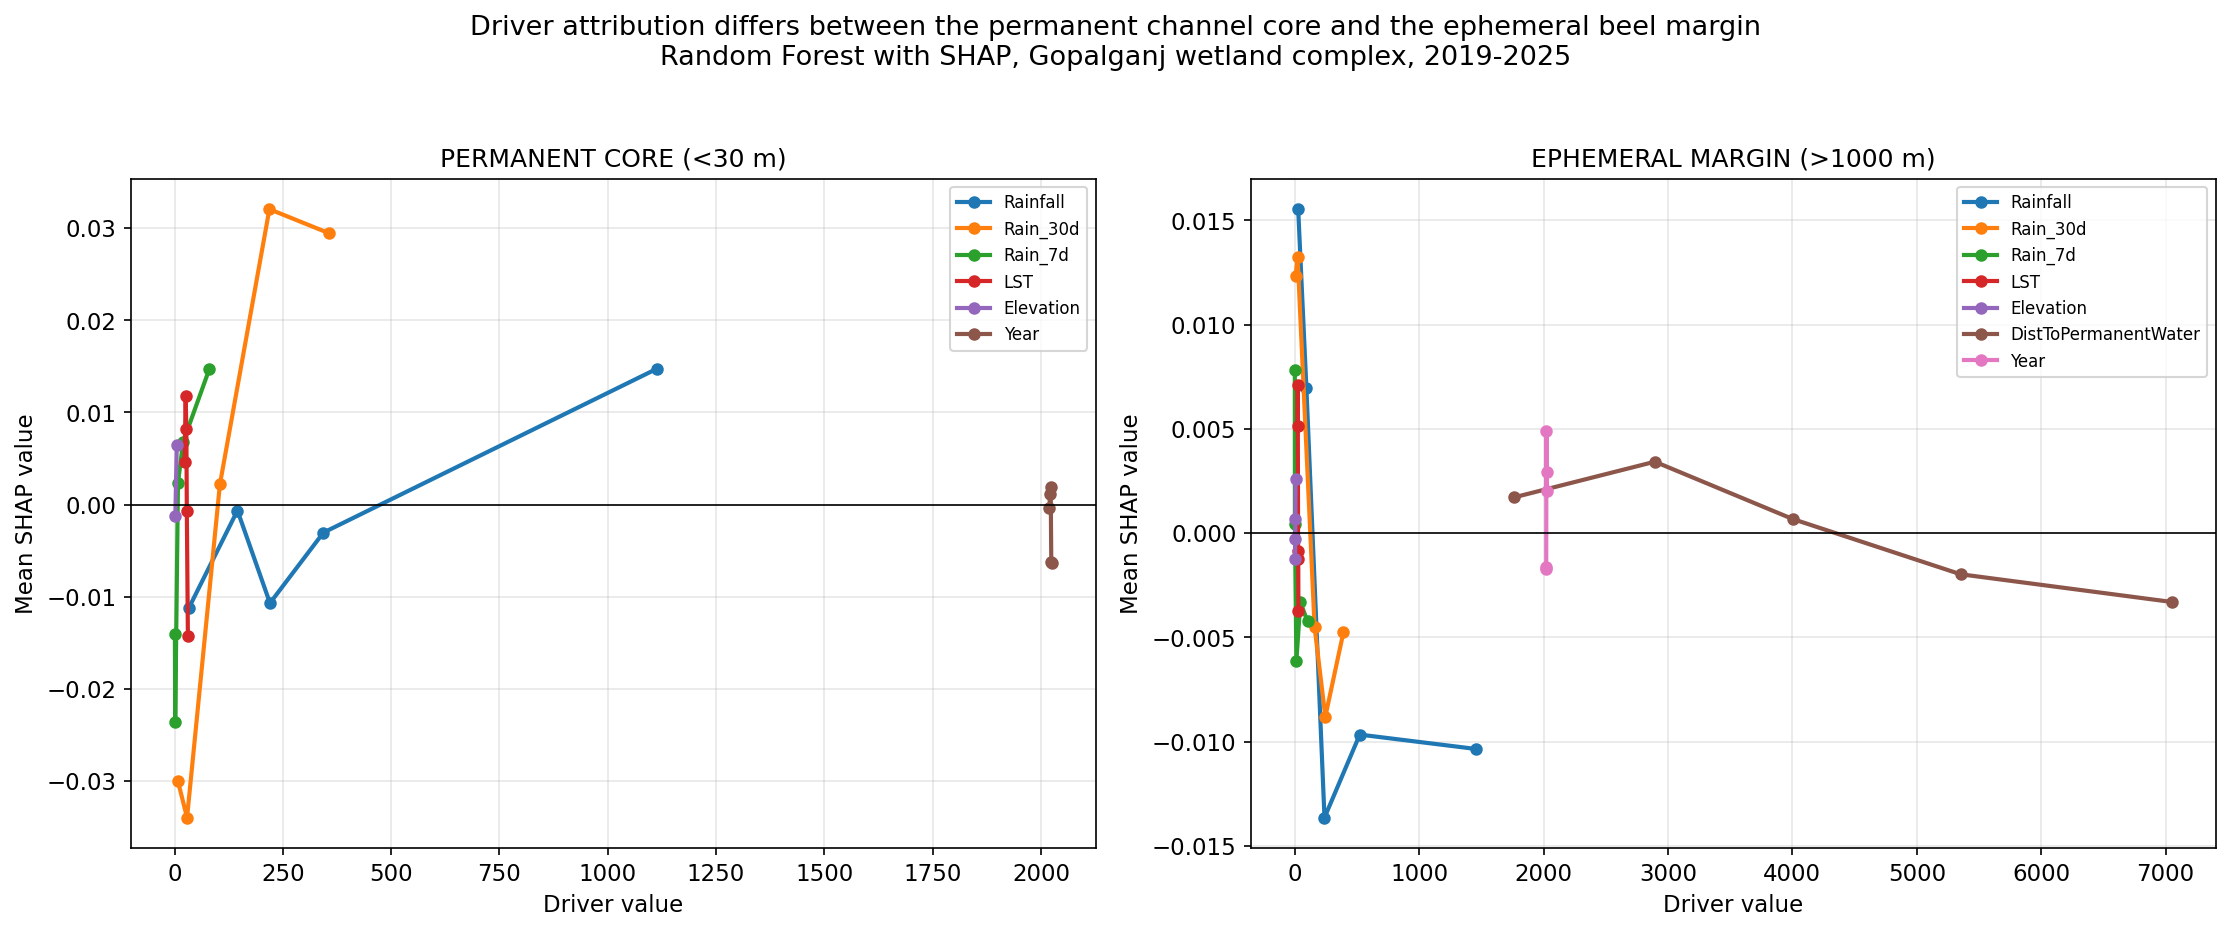

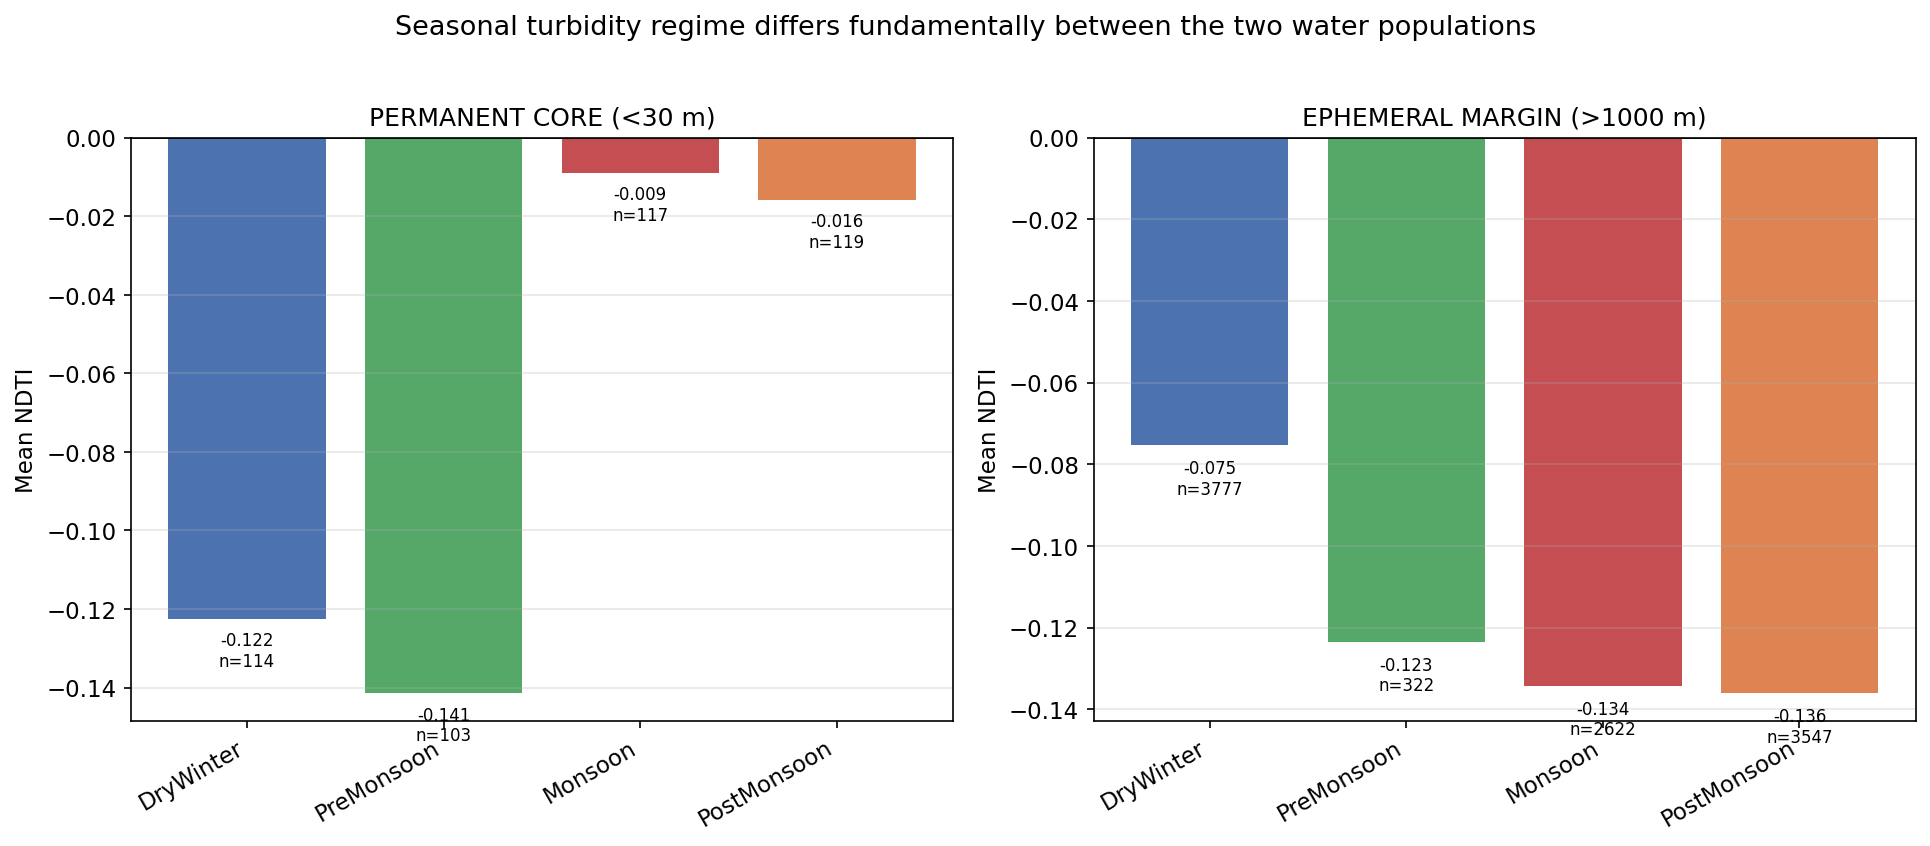

In [14]:
import pandas as pd, numpy as np, json
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import shap, matplotlib.pyplot as plt

df = pd.read_csv('Final_Gopalganj_ML_Samples_FINAL_CORRECTED_V2.csv')
df = df.rename(columns={'DistToWater': 'DistToPermanentWater'})

coords = df['.geo'].apply(lambda s: json.loads(s)['coordinates'])
df['lon'] = coords.apply(lambda c: c[0]); df['lat'] = coords.apply(lambda c: c[1])
df['group'] = df['Year'].astype(str) + '_' + df['Season']

features = ['Rainfall','Rain_30d','Rain_7d','LST','Elevation',
            'DistToPermanentWater','Year']
target = 'NDTI'

strata = {
    'PERMANENT CORE (<30 m)':     df[df['DistToPermanentWater'] < 30].copy(),
    'EPHEMERAL MARGIN (>1000 m)': df[df['DistToPermanentWater'] > 1000].copy(),
}

def safe_shap(sv):
    if isinstance(sv, list):
        sv = sv[0]
    if sv.ndim == 3:
        sv = sv[:, :, 0]
    return sv

def run_stratum(name, sub):
    print('\n' + '='*64)
    print(f'STRATUM: {name}   n = {len(sub)}')
    print('='*64)

    X = sub[features].copy(); y = sub[target].copy()
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                max_features='sqrt', random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_tr)
    p = rf.predict(X_te)

    print('random split  R2 =', round(r2_score(y_te, p), 4),
          '| RMSE =', round(np.sqrt(((y_te-p)**2).mean()), 4))

    ng = sub['group'].nunique()
    if ng > 3:
        sc = cross_val_score(rf, X, y, groups=sub['group'],
                             cv=GroupKFold(n_splits=min(7, ng)),
                             scoring='r2', n_jobs=-1)
        print('grouped CV    R2 =', round(sc.mean(), 4), '+/-', round(sc.std(), 4))

    expl = shap.TreeExplainer(rf)
    sv = safe_shap(expl.shap_values(X_te))

    rows = []
    for i, f in enumerate(features):
        col = X_te[f]
        if col.nunique() < 5:
            print(f'  [skip {f}: only {col.nunique()} unique values]')
            continue
        q = pd.qcut(col, 5, labels=False, duplicates='drop')
        q = pd.Series(q, index=X_te.index).astype(float)
        for k in sorted(q.dropna().unique()):
            m = q == k
            if m.sum() < 5:
                continue
            rows.append({'feature': f, 'quintile': int(k) + 1,
                         'feat_val': float(col[m].mean()),
                         'mean_SHAP': float(np.mean(sv[m, i]))})
    res = pd.DataFrame(rows)

    print('\n--- driver direction (Q1 vs Q5 mean SHAP) ---')
    direction = {}
    for f in features:
        s = res[res.feature == f]
        if s.empty: continue
        lo = s[s.quintile == s.quintile.min()]['mean_SHAP'].iloc[0]
        hi = s[s.quintile == s.quintile.max()]['mean_SHAP'].iloc[0]
        d = 'INCREASES turbidity' if hi > lo else 'DECREASES turbidity'
        direction[f] = d
        print(f'{f:22s} Q1={lo:+.5f}  Q5={hi:+.5f}  -> {d}')

    print('\n--- seasonal mean NDTI in this stratum ---')
    seas = sub.groupby('Season')['NDTI'].agg(['count','mean']).round(4)
    print(seas.to_string())

    print('\n--- seasonal mean rainfall in this stratum ---')
    print(sub.groupby('Season')['Rainfall'].agg(['count','mean']).round(1).to_string())

    return {'rf': rf, 'X_te': X_te, 'sv': sv, 'res': res,
            'direction': direction, 'seas': seas}

results = {}
for name, sub in strata.items():
    results[name] = run_stratum(name, sub)

# ================= ফিগার =================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, r) in zip(axes, results.items()):
    for f in features:
        s = r['res'][r['res'].feature == f]
        if s.empty: continue
        s = s.sort_values('quintile')
        ax.plot(s['feat_val'], s['mean_SHAP'], '-o', lw=2, ms=5, label=f)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(name, fontsize=12)
    ax.set_xlabel('Driver value'); ax.set_ylabel('Mean SHAP value')
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle('Driver attribution differs between the permanent channel core and the ephemeral beel margin\n'
             'Random Forest with SHAP, Gopalganj wetland complex, 2019-2025',
             fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig('Fig_Stratum_DriverAttribution.png', dpi=300, bbox_inches='tight')
plt.show()

# ফিগার ২: ঋতুভিত্তিক তুলনা দুই স্তরে
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, r) in zip(axes, results.items()):
    s = r['seas']
    s = s.reindex(['DryWinter','PreMonsoon','Monsoon','PostMonsoon'])
    ax.bar(range(len(s)), s['mean'], color=['#4C72B0','#55A868','#C44E52','#DD8452'])
    ax.set_xticks(range(len(s)))
    ax.set_xticklabels(s.index, rotation=30, ha='right')
    ax.set_ylabel('Mean NDTI'); ax.set_title(name, fontsize=12)
    ax.axhline(0, color='black', lw=0.8); ax.grid(alpha=0.3, axis='y')
    for i, (v, n) in enumerate(zip(s['mean'], s['count'])):
        ax.text(i, v + (0.004 if v >= 0 else -0.012), f'{v:+.3f}\nn={n}',
                ha='center', fontsize=8)
fig.suptitle('Seasonal turbidity regime differs fundamentally between the two water populations',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('Fig_Stratum_Seasonal.png', dpi=300, bbox_inches='tight')
plt.show()